# Laboratorio 18: Validación cruzada y comparación de árboles

**Asignatura:** Analítica de Datos  
**Docente:** Luis Miguel Gómez Meneses  
**Universidad Cooperativa de Colombia**

## Objetivo

Comparar árboles de decisión con diferentes profundidades mediante
validación cruzada estratificada y seleccionar una configuración
a partir de su desempeño.

## Pregunta del laboratorio

¿Un árbol más profundo obtiene siempre mejores resultados?

## Ruta de trabajo

1. Cargar Iris y separar entrenamiento y prueba.
2. Evaluar un árbol con cinco pliegues estratificados.
3. Comparar profundidades de 1, 2, 3, 4 y sin límite.
4. Seleccionar una configuración usando la validación cruzada.
5. Entrenar el modelo elegido y evaluarlo en prueba.
6. Escribir una conclusión propia.

La comparación de profundidades utilizará únicamente los datos
de entrenamiento. No usaremos los resultados de prueba para elegir
la configuración.

## 1. Importación de librerías

Utilizaremos:

- **Pandas:** organizar los datos y las tablas de resultados.
- **Matplotlib:** mostrar los resultados gráficamente.
- **Scikit-learn:** cargar Iris, entrenar árboles y evaluar su desempeño.

`StratifiedKFold` construye pliegues conservando las proporciones
de las clases.

`cross_val_score` entrena y evalúa un modelo en cada ronda,
y devuelve las puntuaciones obtenidas.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
SEMILLA = 42

## 2. Preparación de los datos

Usaremos las cuatro medidas de cada flor para predecir su especie:
setosa, versicolor o virginica.

Separaremos las 150 flores en:

- **120 para entrenamiento:** aquí aplicaremos la validación cruzada
  y compararemos las profundidades.
- **30 para prueba:** evaluaremos el modelo elegido al final.

Mantendremos la semilla 42 y la división estratificada del laboratorio
anterior para conservar las mismas observaciones en cada conjunto.

In [2]:
iris = load_iris()
columnas = [
    "longitud_sepalo",
    "ancho_sepalo",
    "longitud_petalo",
    "ancho_petalo"
]
datos = pd.DataFrame(iris.data, columns=columnas)
datos["especie"] = iris.target_names[iris.target]
X = datos[columnas].copy()
y = datos["especie"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEMILLA,
    stratify=y
)
distribucion = pd.DataFrame({
    "Entrenamiento": y_train.value_counts(),
    "Prueba": y_test.value_counts()
}).reindex(iris.target_names)
display(distribucion)
print("Total de flores de entrenamiento:", len(X_train))
print("Total de flores de prueba:", len(X_test))

,Entrenamiento,Prueba
especie,,
setosa,40,10
versicolor,40,10
virginica,40,10


Total de flores de entrenamiento: 120
Total de flores de prueba: 30


### Preguntas de análisis

1. ¿Sobre cuál de los dos conjuntos aplicaremos la validación cruzada?
2. ¿Por qué no debemos usar la exactitud en prueba para elegir
   la profundidad del árbol?

**Respuestas:**

1.
2.

## 3. Validación cruzada con cinco pliegues

Dividiremos las 120 flores de entrenamiento en cinco grupos
de 24 flores, conservando las proporciones de las especies.

En cada ronda:

- Entrenaremos un árbol nuevo con 96 flores.
- Lo evaluaremos con las 24 flores del grupo restante.

Cada grupo se utilizará una vez para validar.
Obtendremos cinco puntuaciones de exactitud.

In [3]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMILLA
)
modelo_base = DecisionTreeClassifier(
    max_depth=3,
    random_state=SEMILLA
)
puntuaciones = cross_val_score(
    modelo_base,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)
resultados_cv = pd.DataFrame({
    "Ronda": range(1, 6),
    "Exactitud (%)": puntuaciones * 100
})
display(resultados_cv.round(2))
print(f"Exactitud media: {puntuaciones.mean():.2%}")
print(
    "Desviación estándar: "
    f"{puntuaciones.std() * 100:.2f} puntos porcentuales"
)

,Ronda,Exactitud (%)
0,1,95.83
1,2,100.00
2,3,95.83
3,4,95.83
4,5,91.67


Exactitud media: 95.83%
Desviación estándar: 2.64 puntos porcentuales


### Preguntas de análisis

3. ¿Cuál fue la mayor exactitud y cuál fue la menor?
4. ¿Qué indica que las cinco puntuaciones sean diferentes?
5. Explica qué representan la exactitud media y la desviación estándar.

**Respuestas:**

3.
4.
5.

## 4. Comparación de profundidades

Evaluaremos árboles con profundidad máxima de 1, 2, 3, 4
y sin límite de profundidad.

Todos utilizarán los mismos cinco pliegues para que la comparación
se realice con las mismas flores en cada ronda.

Compararemos:

- **Exactitud media:** desempeño promedio en validación.
- **Desviación estándar:** variación entre las cinco puntuaciones.

La opción "Sin límite" permite crecer hasta que se cumplan
otros criterios de parada; no significa que el árbol crezca indefinidamente.

In [4]:
profundidades = [1, 2, 3, 4, None]
filas = []
for profundidad in profundidades:
    modelo = DecisionTreeClassifier(
        max_depth=profundidad,
        random_state=SEMILLA
    )
    scores = cross_val_score(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )
    filas.append({
        "Profundidad": (
            str(profundidad) if profundidad is not None
            else "Sin límite"
        ),
        "Exactitud media (%)": scores.mean() * 100,
        "Desviación estándar (pp)": scores.std() * 100
    })
comparacion = pd.DataFrame(filas)
display(comparacion.round(2))

,Profundidad,Exactitud media (%),Desviación estándar (pp)
0,1,66.67,0.00
1,2,94.17,2.04
2,3,95.83,2.64
3,4,94.17,2.04
4,Sin límite,95.00,1.67


### Preguntas de análisis

6. El árbol de profundidad 1 obtuvo una exactitud media del 66,67 %
   y una desviación estándar de 0.
   ¿Que sus resultados sean iguales en todas las rondas significa
   que sea un buen modelo? Justifica.

7. Al aumentar la profundidad de 2 a 3, la exactitud media pasó
   del 94,17 % al 95,83 %. Sin embargo, al aumentarla a 4,
   volvió al 94,17 %.
   ¿Qué indica esto sobre la relación entre profundidad y desempeño?

8. El árbol de profundidad 3 obtuvo una media del 95,83 %
   y una desviación estándar de 2,64 puntos porcentuales.
   El árbol sin límite obtuvo una media del 95,00 %
   y una desviación de 1,67 puntos porcentuales.
   ¿Cuál obtuvo mayor exactitud media y cuál presentó menor variación?

9. Si el criterio acordado es seleccionar la mayor exactitud media
   de validación cruzada, ¿qué profundidad elegirías?
   ¿Por qué no debemos utilizar el conjunto de prueba para decidir?

**Respuestas:**

6.
7.
8.
9.

## 5. Entrenamiento y evaluación del modelo seleccionado

Seleccionamos la profundidad máxima de **3** porque obtuvo la mayor
exactitud media en la validación cruzada.

Ahora entrenaremos un nuevo árbol con las **120 flores de entrenamiento**
y lo evaluaremos con las **30 flores de prueba**.

La validación cruzada permitió elegir la profundidad.
La evaluación en prueba permite medir el desempeño del modelo elegido.

No modificaremos la configuración a partir del resultado en prueba.

Profundidad seleccionada: 3
Aciertos en prueba: 29 de 30
Exactitud en prueba: 96.67%


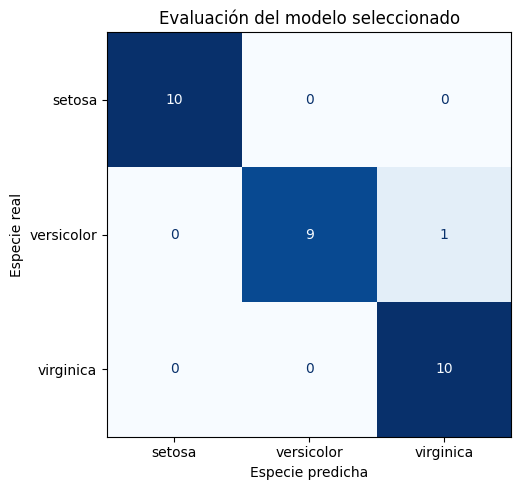

In [5]:
profundidad_elegida = 3
modelo_final = DecisionTreeClassifier(
    max_depth=profundidad_elegida,
    random_state=SEMILLA
)
modelo_final.fit(X_train, y_train)
y_pred_final = modelo_final.predict(X_test)
exactitud_final = accuracy_score(y_test, y_pred_final)
aciertos = int((y_pred_final == y_test.to_numpy()).sum())
print("Profundidad seleccionada:", profundidad_elegida)
print(f"Aciertos en prueba: {aciertos} de {len(y_test)}")
print(f"Exactitud en prueba: {exactitud_final:.2%}")
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    labels=modelo_final.classes_,
    display_labels=modelo_final.classes_,
    cmap="Blues",
    colorbar=False,
    ax=ax
)
ax.set_title("Evaluación del modelo seleccionado")
ax.set_xlabel("Especie predicha")
ax.set_ylabel("Especie real")
plt.tight_layout()
plt.show()

## 6. Conclusión del laboratorio 18

Redacta una conclusión de **5 a 8 líneas** que integre los siguientes aspectos:

- ¿Qué profundidad seleccionaste y qué resultado de validación cruzada
  respalda esa elección?
- ¿Aumentar la profundidad mejoró siempre la exactitud? Utiliza la tabla
  comparativa para justificar tu respuesta.
- ¿Cómo se compara la exactitud media de validación cruzada con la
  exactitud obtenida en prueba?
- ¿Qué confusión entre especies presentó el modelo en la evaluación final?
- ¿Por qué seleccionamos la profundidad con validación cruzada y
  reservamos los datos de prueba para la evaluación final?

**Escribe aquí tu conclusión:**